In [1]:
import os
import emcee
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

import belfast.mcmc_utils as mcmc
from belfast.target_utils import query_data
from belfast.target_definition import Target
from belfast.paths import REPO_ROOT, RESULTS_DIR, DATA_DIR

%load_ext autoreload
%autoreload 2

# Prepare data


## Querying data from 2MASS, Tycho-2, and Gaia DR3

In [2]:
cluster = ''
target_name = 'kappa Andromedae'
extinction = 0.029

In [3]:
target_name = target_name.strip()
obs_mags, obs_err_mags, vsini_obs, vsini_obs_err, parallax_obs, parallax_obs_err,\
    EBP_RP_obs, EBP_RP_obs_lower, EBP_RP_obs_upper, additional_info = query_data(target_name,  return_df=False)

Target : kappa Andromedae
IDs    : Gaia DR3 1926476042681491712 | HIP 116805 | HD 222439 | 2MASS J23402449+4420021
-----------------------------------------------------------------------------------------------------------------------------
General info                       | Gaia DR3                                      | Tycho-2                                 
RA            : 355.1021           | G        :   4.1480 ±   0.0015 mag            | B_T :   4.0510 ±   0.0140 mag           
Dec           : 44.3339            | G_BP     :   4.0899 ±   0.0016 mag            | V_T :   4.1260 ±   0.0090 mag           
Spectral Type : B9IVn              | G_RP     :   4.1681 ±   0.0025 mag            | ----------------------------------------
Object Type   : PM*                | Parallax :  19.4064 ±   0.2104 mas            | 2MASS                                   
Distance      : 51.53 ± 0.56 pc    | RUWE     :   1.9080                           | J   :   4.6240 ±   0.2640 mag           
   

In [4]:
vsini_obs, vsini_obs_err = 176, 17.6 # for kappa Andromedae A

In [5]:
# set extinction

extinction_err = 0.01
extinction_type='A_V' #' A_V' or 'EB_V', or 'EBP_RP'

# Set Target

In [6]:
target = Target(name = target_name,
                bands_list = ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks'],
                obs_mags = obs_mags,
                obs_err_mags = obs_err_mags,
                vsini_obs = vsini_obs,
                vsini_obs_err = vsini_obs_err,
                parallax_obs = parallax_obs,
                parallax_obs_err = parallax_obs_err,
                sigma_adjustment_parameter = 1,
                extinction_parameter = True,
                true_values=False,
                )

In [7]:
# sample all parameters
target.add_info(cluster=cluster,
                sampling_variables_list = ['Mini', 'Age', 'MH', 'omega_ini', 'Inclination', 'parallax'],
                extinction=extinction,
                extinction_err=extinction_err,
                extinction_type=extinction_type
)

In [ ]:
# # if you want to sample with fixed metallicity [M/H] = 0.0, please give the value by target.known_parameter()
# target.add_info(cluster=cluster,
#                 sampling_variables_list = ['Mini', 'logAge', 'omega_ini', 'Inclination', 'parallax'], # not sampling MH
#                 extinction=extinction,
#                 extinction_err=extinction_err,
#                 extinction_type=extinction_type
# )
#
# target.known_parameter(known_MH=0) # giving fixed MH here


In [ ]:
# # If assuming non-rotation
# target.add_info(cluster=cluster,
#                 sampling_variables_list = ['Mini', 'logAge', 'MH', 'parallax'], # not sampling omega_ini and inclination
#                 extinction=extinction,
#                 extinction_err=extinction_err,
#                 extinction_type=extinction_type
# )
#
# target.known_parameter(known_omega_ini=1e-8, known_Inclination=1e-8)

# Setting method

In [8]:
# Standard Regularization + METHOD DIRECT

target.set_method(
    grids_type='Mini',
    label_list=[0, 1],
    METHOD='DIRECT',
)

****************************************************************************************************
Using PARSEC isochrones with Mini grids and DIRECT method.
****************************************************************************************************
Age_grid: [1.0, 2001.01341407] Myr
Age_grid shape: (219,)
Loaded regularized Mini grid using ndimage.map_coordinates.
grid_type: with_inc
label_list: [0, 1]
interp_variable_list: ['Mini', 'Age', 'MH', 'omega_ini', 'Inclination']
interp_output_list: ['Mass', 'omega', 'logL', 'logTe', 'Req', 'Rpol', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
grid_outputs shape: (1392, 219, 13, 7, 11, 14)
grid_bounds shape: (219, 13, 7, 11, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 16298.61 MB (15.92 GB)
Axis spacing:
  Mini           : uniform
  Age            : non-uniform
  MH             : non-uniform
  omega_ini      : non-uniform
  Inclination    : non-uniform

In [ ]:
# # Standard Regularization + METHOD PARS
#
# target.set_method(
#     grids_type='Mini',
#     label_list=[0, 1],
#     METHOD='PARS',
# )

In [ ]:
# # # Reparameterized Regularization + METHOD DIRECT
#
# target.set_method(
#     grids_type='u',
#     label_list=[0, 1],
#     METHOD='DIRECT',
# )

In [ ]:
# Reparameterized Regularization + METHOD PARS
#
# target.set_method(
#     grids_type='u',
#     label_list=[0, 1],
#     METHOD='PARS',
# )

In [ ]:
# # MIST isochrones + METHOD PARS
#
# target.set_method(
#     grids_type='Mini',
#     iso_name='MIST',
#     METHOD='PARS',
# )

# Sampling

In [9]:
target.interp_upper_limit

array([1.40000000e+01, 2.00101341e+03, 3.36310000e-01, 9.90000000e-01,
       1.57100000e+00])

In [10]:
# Set initial states and prior distributions for sampling.

target.set_sampling(n_walkers=30,
                    # MH_prior=logp_MH,
                    # MH_prior= lambda x: norm.logpdf(x, loc=-0.08, scale=0.10),
                    inclination_prior = lambda x: norm.logpdf(x, loc=np.deg2rad(30), scale=np.deg2rad(6)),
                    extinction_prior = lambda x: norm.logpdf(x, loc=extinction, scale=extinction_err),
                    )

Sampling parameter space:
Parameter           Min        Max
----------------------------------
Mini             0.0900    14.0000
Age              1.0000  2001.0134
MH              -2.1917     0.3363
omega_ini        0.0000     0.9900
Inclination      0.0000     1.5708
parallax        14.4064    24.4064
sigma            0.0000     0.1000
extinction       0.0000     1.0000


Estimating rough mass...


100%|██████████| 3000/3000 [00:15<00:00, 189.87it/s]

Rough mass is 2.67 M_sun.
====> Using default Vrot prior: 2.45-2.95 Msun
Running a test with 3000 samples...



100%|██████████| 3000/3000 [00:17<00:00, 169.42it/s]


acceptance ratio:
	0.22 0.22 0.23 0.20 0.22 0.24 0.24 0.24 0.22 
	0.22 0.22 0.25 0.22 0.22 0.20 0.21 0.22 0.23 
	0.22 0.20 0.23 0.23 0.24 0.22 0.22 0.21 0.21 
	0.24 0.23 0.22 
mean acceptance ratio: 0.224
n_steps/60: 50.00
autocorrelation time: [ 84  98  99 113  76  69 106 134]


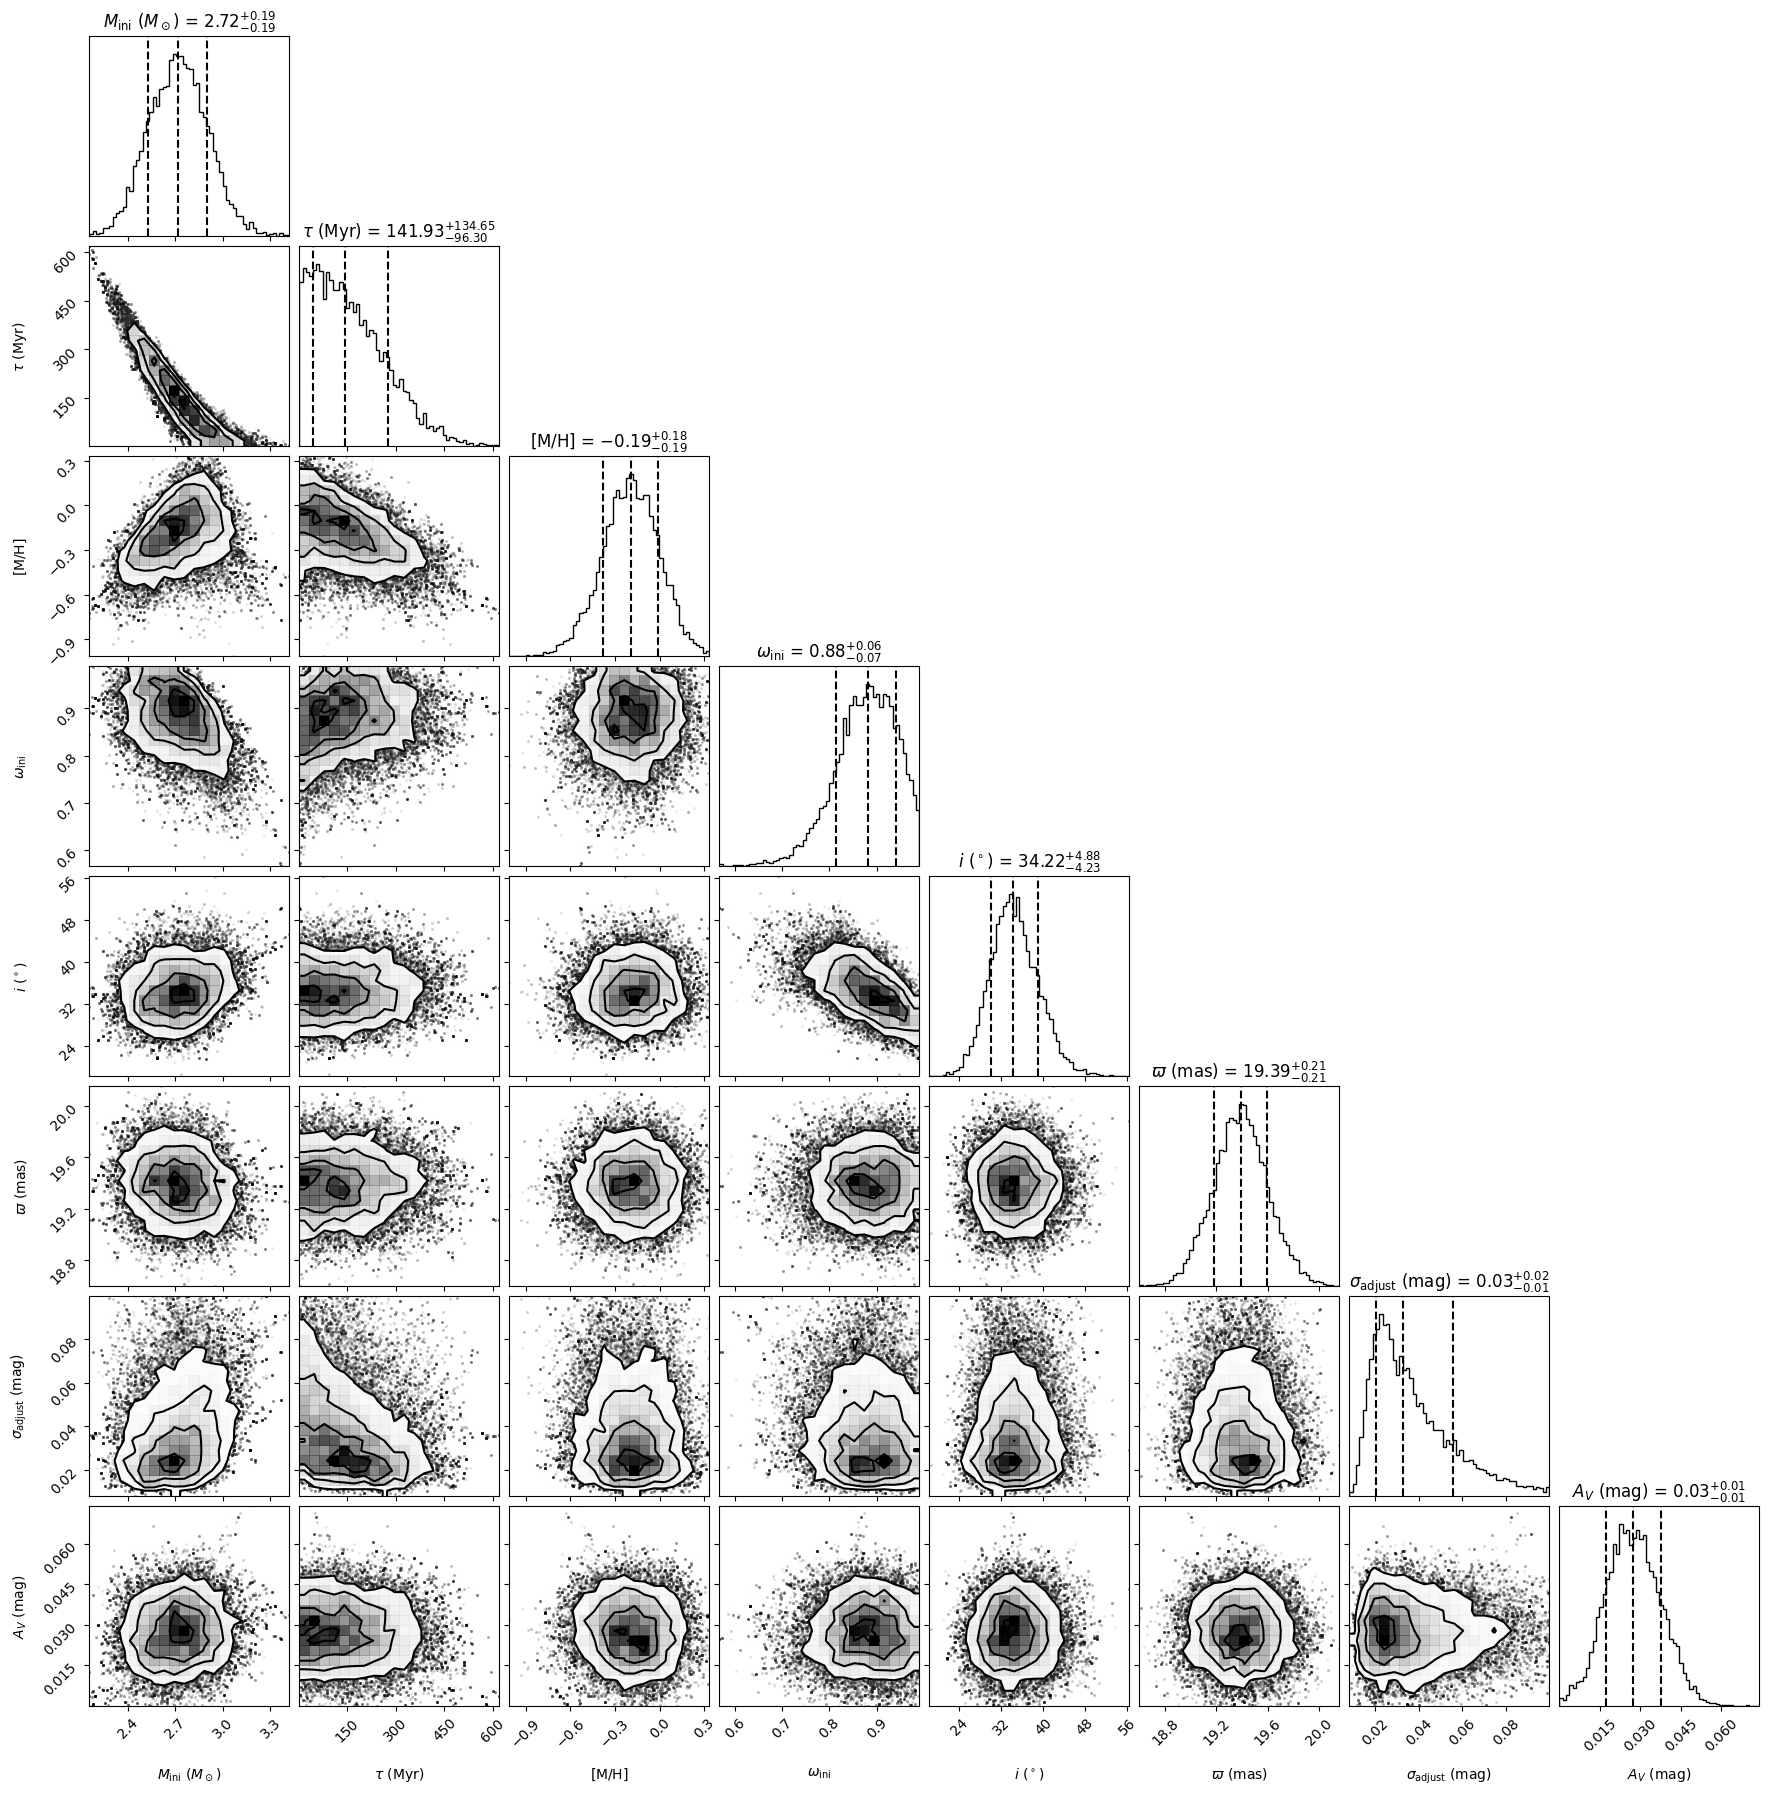

In [11]:
# quick-look tests

target.emcee_moves = [
    (emcee.moves.StretchMove(a=2.0),         0.50),
    (emcee.moves.DEMove(gamma0=0.40),        0.20),
    (emcee.moves.DESnookerMove(),            0.15),
    (emcee.moves.KDEMove(),                  0.15),
]

# target.emcee_moves = [
#     (emcee.moves.StretchMove(a=2.0),         0.95),
#     (emcee.moves.KDEMove(),                  0.05),
# ]

# target.Vrot_prior = None
# target.Vrot_prior = lambda x: 0
mcmc.target = target

sampler_test, target = mcmc.run_test_sampling(
    # n_steps_evaluate=1000,
    n_steps_test=3000,
    n_processes=2,
    save_samples=False,
)

In [12]:
# Run sampling!
# Set max time for running and processes for parallel

mcmc.target = target
sampler = mcmc.run_sampling(initial_steps = 10000, # the interval for checking convergence (e.g. 10000, 30000, 60000)
                            max_hours=10, # hours; if reaching max_hours, stop sampling anyway.
                            n_processes=8, # the number of threads used for parallel sampling.
                            )

# Play sounds to indicate completion. (For Mac only.)
for _ in range(3):
	os.system("afplay /System/Library/Sounds/Glass.aiff")

🔄 Initial sampling: 10000 steps


100%|██████████| 10000/10000 [00:51<00:00, 194.59it/s]


🚀 Standard criteria: usable N/τ ≥ 70, τ_diff < 20%

🔍 Checkpoint @ 10000 steps (elapsed 0h 0m)
  τ₀․₅=132.2, τ₀․₃=120.3, τ_diff=9.0%
  Usable N/τ after burn=10τ: 65.7 / 70
⏱ Next: 1322 steps (missing 4.3τ, planned 10.0τ)


100%|██████████| 1322/1322 [00:06<00:00, 193.42it/s]



🔍 Checkpoint @ 11322 steps (elapsed 0h 0m)
  τ₀․₅=137.7, τ₀․₃=113.4, τ_diff=17.7%
  Usable N/τ after burn=10τ: 72.2 / 70
⏱ Next: 1378 steps (missing 0.0τ, planned 10.0τ)


100%|██████████| 1378/1378 [00:06<00:00, 197.93it/s]



🔍 Checkpoint @ 12700 steps (elapsed 0h 1m)
  τ₀․₅=137.1, τ₀․₃=125.8, τ_diff=8.3%
  Usable N/τ after burn=10τ: 82.6 / 70
✅ Converged: τ stable for 2 checkpoints and usable N/τ ≥ 70
Total sampling time: 00:01:05
Total MCMC steps of each walker: 12700


📏 τ₀․₅=137.1, τ₀․₃=125.8, τ_late=137.1 → burn-in=1371
Results and plots will be saved at
	/Users/ziyinggu/Programming/GitHub/BELFAST/results/kappa_Andromedae_PARSEC_DIRECT_Mini_grid_sigma1_A_V_G-Tomo_A_V_prior
True values: [None, None, None, None, None, None]
Finished saving plots.


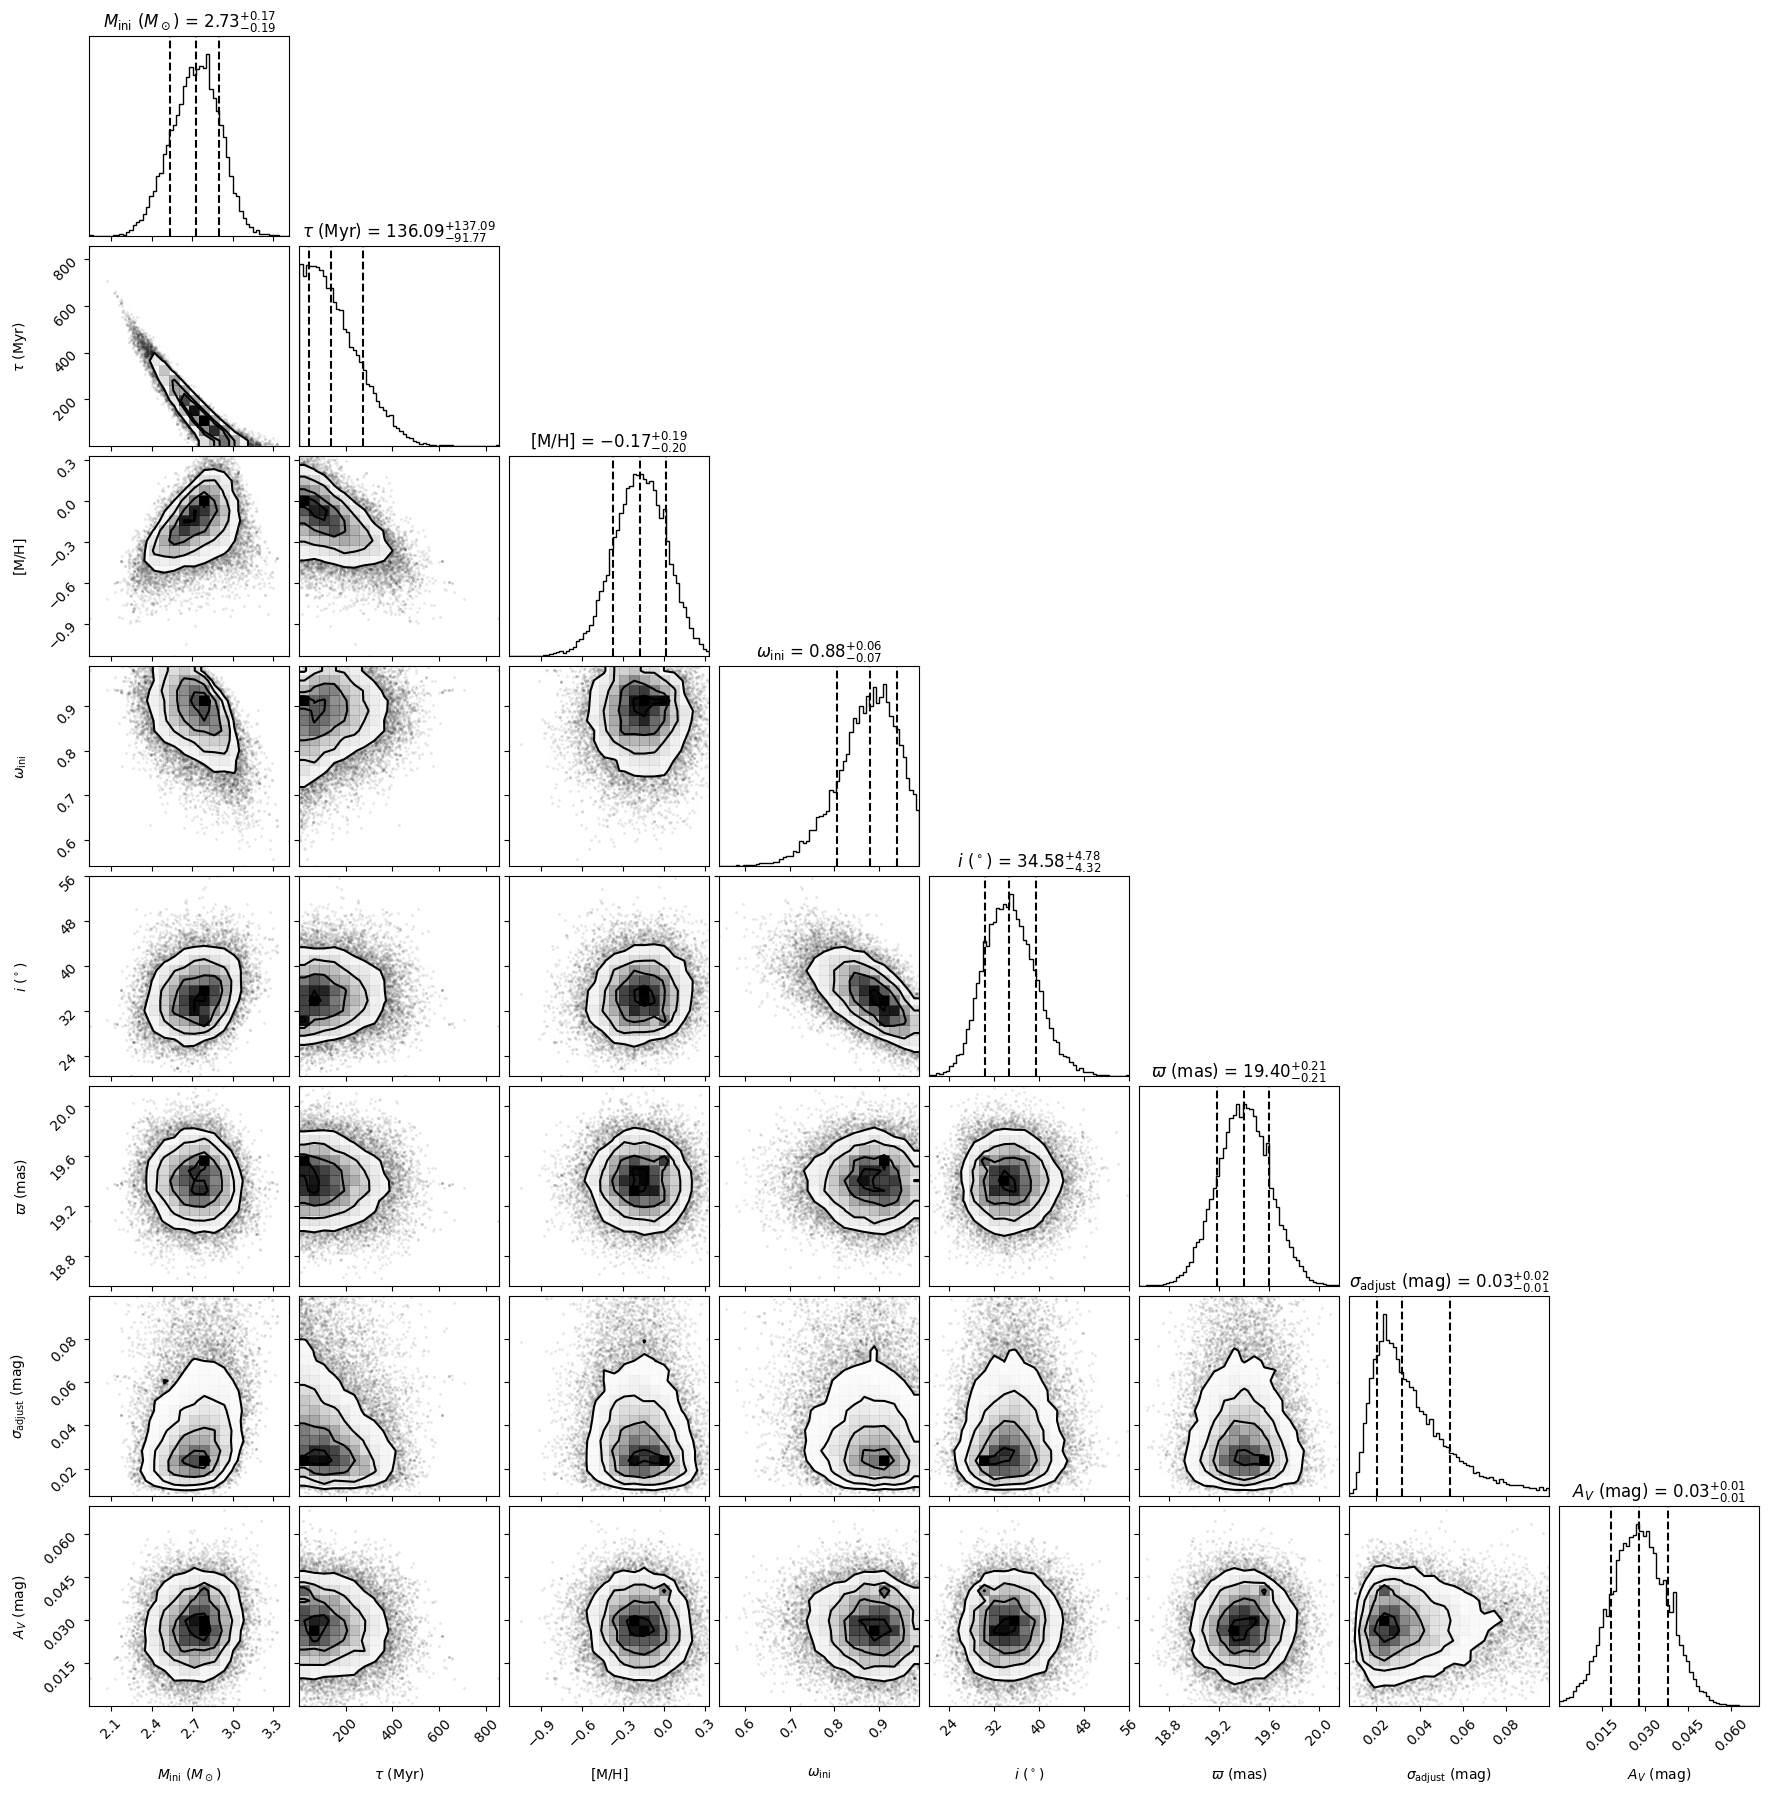

In [13]:
 # Save figures and samples, including corner plot, trace plots for all walkers, target file, and summary of results.

mcmc.target = target
mcmc.save_and_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior')

In [15]:
target.check_risk()


## Posterior

Samples             (12700, 30, 8) | Blobs              (12700, 30, 21)
After discard              339,870 | Batch size                   5,000

## Boundary grid

MH             -1.49235 -- 0.33637 | omega               0.300 -- 0.990
MH grid                       N=11 | omega grid                     N=6
Posterior Mini      1.936 -- 3.419 | Boundary Mini       1.800 -- 3.719
Mass grid                    N=193 | Low-M extrap.                  N=2


Classifying samples: 100%|██████████| 339870/339870 [00:15<00:00, 21940.07samples/s]


## Classification

Valid                      339,870 | Invalid                          0
Safe                       339,870 | Risky                            0
P(safe)                    1.00000 | P(risky)                   0.00000
